# 01 · Baseline exploration
Loads the synthetic campus dataset, resamples it, and plots the **4 PM – 8 PM evening demand spike**.

Run `python src/generate_data.py` first if `data/raw/` is empty.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/raw/hourly_consumption.csv", parse_dates=["timestamp"])
monthly = pd.read_csv("../data/raw/monthly_totals.csv")
df.head()

,timestamp,building,building_type,temperature,kWh_consumed
0,2026-06-01 00:00:00,B1_Hostel_A,hostel,26.2,42.15
1,2026-06-01 01:00:00,B1_Hostel_A,hostel,23.2,38.70
2,2026-06-01 02:00:00,B1_Hostel_A,hostel,25.3,42.37
3,2026-06-01 03:00:00,B1_Hostel_A,hostel,25.4,42.94
4,2026-06-01 04:00:00,B1_Hostel_A,hostel,21.3,43.88


## Missing data
Hourly gaps simulate buildings where only the monthly bill is known.

In [2]:
df.groupby("building")["kWh_consumed"].apply(lambda s: s.isna().mean()).rename("missing_frac").round(3)

building
B1_Hostel_A    0.130
B2_Hostel_B    0.098
B3_Academic    0.185
B4_Library     0.141
B5_Lab         0.152
Name: missing_frac, dtype: float64

## Resampling
Hourly → daily totals (per building) and average hourly profile.

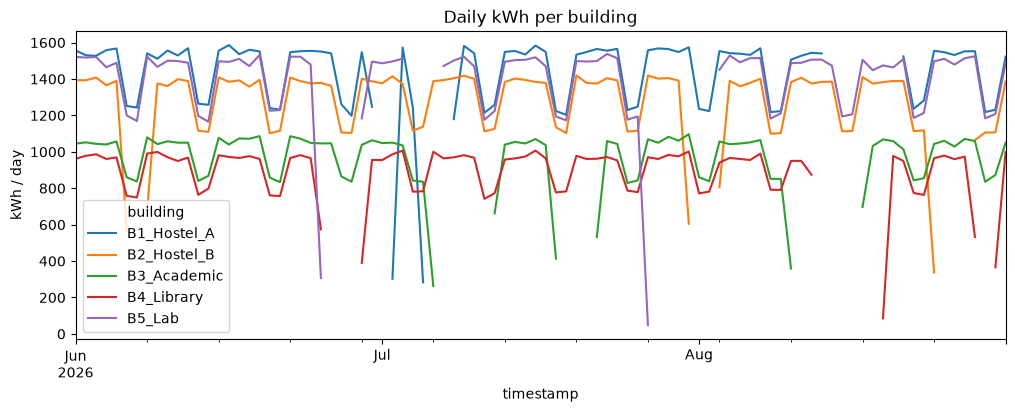

In [3]:
wide = df.pivot(index="timestamp", columns="building", values="kWh_consumed")

daily = wide.resample("D").sum(min_count=1)       # NaN for days fully missing
weekly = wide.resample("W").mean()

ax = daily.plot(figsize=(12, 4), title="Daily kWh per building")
ax.set_ylabel("kWh / day")
plt.show()

## The 4 PM – 8 PM demand spike
Average load by hour of day, campus-wide and per building.

In [ ]:
profile = df.groupby([df["timestamp"].dt.hour, "building"])["kWh_consumed"].mean().unstack()
campus = profile.sum(axis=1)

fig, ax = plt.subplots(figsize=(10, 5))
ax.axvspan(16, 20, color="tab:red", alpha=0.12, label="Peak window 4–8 PM")
ax.plot(campus.index, campus.values, color="black", lw=2.5, label="Campus total")
for b in profile.columns:
    ax.plot(profile.index, profile[b], lw=1, alpha=0.7, label=b)
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("Hour of day")
ax.set_ylabel("Avg kWh")
ax.set_title("Average hourly demand profile")
ax.legend(fontsize=8, ncol=2)
plt.show()

peak_share = campus.loc[16:19].sum() / campus.sum()  # hours starting 4-7 PM
print(f"4–8 PM accounts for {peak_share:.1%} of daily campus consumption")